In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

RANDOM_STATE = 42
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("wine_semi_supervised_dataset.csv")
print("Dataset Shape (Rows, Columns):", df.shape)
df.head(10)

Dataset Shape (Rows, Columns): (178, 15)


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_cultivar
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,NaN
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,NaN
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,NaN
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0.0
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0.0
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,NaN
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,NaN
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0.0
8,9,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,NaN
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,NaN


In [3]:
known_count = df["wine_cultivar"].notna().sum()
missing_count = df["wine_cultivar"].isna().sum()

print(f"Total wine samples : {len(df)}")
print(f"Known labels       : {known_count} ({known_count/len(df)*100:.1f}%)")
print(f"Missing (NaN)      : {missing_count} ({missing_count/len(df)*100:.1f}%)")
print("\nBreakdown of target values:")
print(df["wine_cultivar"].value_counts(dropna=False).sort_index())

Total wine samples : 178
Known labels       : 53 (29.8%)
Missing (NaN)      : 125 (70.2%)

Breakdown of target values:
wine_cultivar
0.0     18
1.0     21
2.0     14
NaN    125
Name: count, dtype: int64


In [4]:
feature_cols = [col for col in df.columns if col not in ["sample_id", "wine_cultivar"]]

print(f"Number of input features: {len(feature_cols)}")
print("Feature names:", feature_cols)

Number of input features: 13
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [5]:
labelled_df = df[df["wine_cultivar"].notna()].copy()
unlabelled_df = df[df["wine_cultivar"].isna()].copy()

X_labelled = labelled_df[feature_cols]
y_labelled = labelled_df["wine_cultivar"].astype(int)

X_unlabelled = unlabelled_df[feature_cols]

print("Labelled rows shape   :", X_labelled.shape)
print("Unlabelled rows shape :", X_unlabelled.shape)

Labelled rows shape   : (53, 13)
Unlabelled rows shape : (125, 13)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_labelled,
    y_labelled,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_labelled
)

print("Known samples for training :", len(X_train))
print("Known samples for testing  :", len(X_test))

Known samples for training : 39
Known samples for testing  : 14


In [7]:
scaler = StandardScaler()

# Fit only on training data to avoid data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_unlabelled_scaled = scaler.transform(X_unlabelled)

# Combine training + unlabelled features for clustering
X_cluster_pool = np.vstack([X_train_scaled, X_unlabelled_scaled])

print("Total samples available for clustering:", X_cluster_pool.shape[0])

Total samples available for clustering: 164


In [8]:
k_range = range(2, 9)
inertias = []
  bb
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_cluster_pool)
    inertias.append(km.inertia_)
    print(f"K = {k} -> Inertia = {km.inertia_:.2f}")

C:\Users\dell\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\dell\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\dell\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\dell\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

K = 2 -> Inertia = 1466.70
K = 3 -> Inertia = 1104.14
K = 4 -> Inertia = 1015.52
K = 5 -> Inertia = 952.46
K = 6 -> Inertia = 896.87
K = 7 -> Inertia = 849.41


C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

K = 8 -> Inertia = 788.10


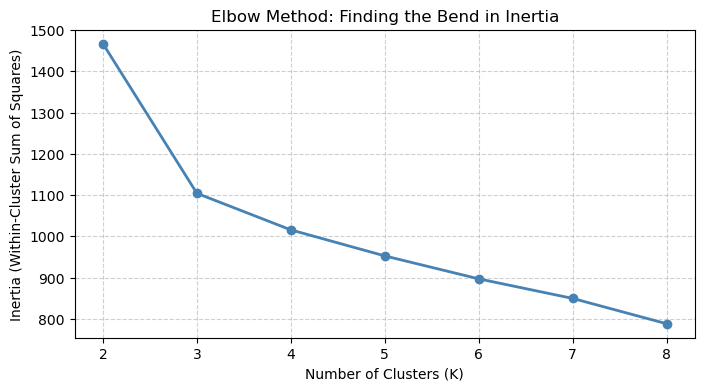

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, marker="o", linewidth=2, color="steelblue")
plt.title("Elbow Method: Finding the Bend in Inertia")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(k_range))
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [10]:
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster_pool)
    score = silhouette_score(X_cluster_pool, labels)
    silhouette_scores.append(score)
    print(f"K = {k} -> Silhouette Score = {score:.4f}")

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

K = 2 -> Silhouette Score = 0.2558
K = 3 -> Silhouette Score = 0.2929
K = 4 -> Silhouette Score = 0.2718
K = 5 -> Silhouette Score = 0.2099
K = 6 -> Silhouette Score = 0.1511
K = 7 -> Silhouette Score = 0.1769
K = 8 -> Silhouette Score = 0.2115


C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


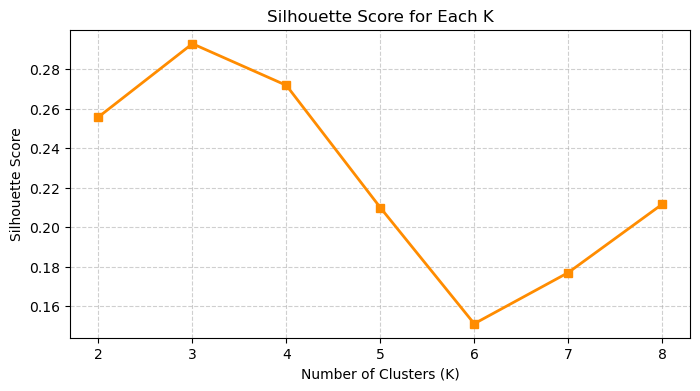

Best K suggested by Elbow + Silhouette Score: K = 3


In [11]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), silhouette_scores, marker="s", linewidth=2, color="darkorange")
plt.title("Silhouette Score for Each K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_range))
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

optimal_k = list(k_range)[int(np.argmax(silhouette_scores))]
print(f"Best K suggested by Elbow + Silhouette Score: K = {optimal_k}")

In [13]:
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_cluster_pool)

train_clusters = kmeans.predict(X_train_scaled)
unlabelled_clusters = kmeans.predict(X_unlabelled_scaled)

print("Cluster IDs assigned to training samples   :", np.unique(train_clusters, return_counts=True))
print("Cluster IDs assigned to unlabelled samples :", np.unique(unlabelled_clusters, return_counts=True))

Cluster IDs assigned to training samples   : (array([0, 1, 2], dtype=int32), array([11, 15, 13]))
Cluster IDs assigned to unlabelled samples : (array([0, 1, 2], dtype=int32), array([35, 43, 47]))


C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [14]:
cluster_to_target = {}
cluster_confidence = {}

for cid in range(optimal_k):
    known_in_cluster = y_train.to_numpy()[train_clusters == cid]
    if len(known_in_cluster) > 0:
        proportions = pd.Series(known_in_cluster).value_counts(normalize=True)
        majority_class = int(proportions.index[0])
        confidence = float(proportions.iloc[0])
        cluster_to_target[cid] = majority_class
        cluster_confidence[cid] = confidence
        print(f"Cluster {cid} -> Majority Target: {majority_class} (Confidence: {confidence*100:.1f}%)")

Cluster 0 -> Majority Target: 2 (Confidence: 90.9%)
Cluster 1 -> Majority Target: 0 (Confidence: 86.7%)
Cluster 2 -> Majority Target: 1 (Confidence: 100.0%)


In [15]:
CONFIDENCE_THRESHOLD = 0.70

accepted_indices = []
pseudo_y_list = []

for idx, cid in enumerate(unlabelled_clusters):
    cid = int(cid)
    if cid in cluster_to_target and cluster_confidence[cid] >= CONFIDENCE_THRESHOLD:
        accepted_indices.append(idx)
        pseudo_y_list.append(cluster_to_target[cid])

X_pseudo = X_unlabelled.iloc[accepted_indices].copy()
y_pseudo = np.array(pseudo_y_list, dtype=int)

# Also show the filled dataset so students can see NaNs replaced!
df_filled = df.copy()
filled_row_indices = unlabelled_df.iloc[accepted_indices].index
df_filled.loc[filled_row_indices, "wine_cultivar"] = y_pseudo

print(f"Total NaN rows originally : {len(X_unlabelled)}")
print(f"Rows filled with pseudo-labels : {len(X_pseudo)}")
print(f"Remaining NaN rows : {df_filled['wine_cultivar'].isna().sum()}")
df_filled.head(10)

Total NaN rows originally : 125
Rows filled with pseudo-labels : 125
Remaining NaN rows : 0


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_cultivar
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0.0
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0.0
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0.0
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0.0
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0.0
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0.0
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0.0
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0.0
8,9,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0.0
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0.0


In [17]:
df_filled["wine_cultivar"].unique()

array([0., 1., 2.])

In [19]:
X_semi_train = pd.concat([X_train, X_pseudo], axis=0)
y_semi_train = np.concatenate([y_train.to_numpy(), y_pseudo])

print("Original small training set size       :", len(X_train))
print("New semi-supervised training set size  :", len(X_semi_train))

Original small training set size       : 39
New semi-supervised training set size  : 164


In [20]:
semi_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
semi_model.fit(X_semi_train, y_semi_train)

y_pred_semi = semi_model.predict(X_test)
semi_acc = accuracy_score(y_test, y_pred_semi)

print(f"Semi-Supervised Model Test Accuracy: {semi_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_semi))

Semi-Supervised Model Test Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5
           2       1.00      1.00      1.00         4

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



In [21]:
sup_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
sup_model.fit(X_train, y_train)

y_pred_sup = sup_model.predict(X_test)
sup_acc = accuracy_score(y_test, y_pred_sup)

results_df = pd.DataFrame({
    "Approach": ["Supervised Only (Small Labeled Data)", "Semi-Supervised (Labeled + Pseudo-Labeled)"],
    "Training Samples Used": [len(X_train), len(X_semi_train)],
    "Test Accuracy (%)": [round(sup_acc * 100, 2), round(semi_acc * 100, 2)]
})
results_df

,Approach,Training Samples Used,Test Accuracy (%)
0,Supervised Only (Small Labeled Data),39,100.0
1,Semi-Supervised (Labeled + Pseudo-Labeled),164,100.0


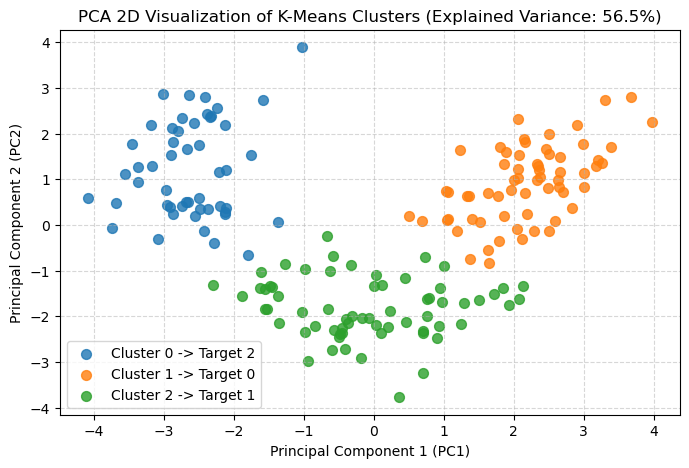

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_all_scaled = scaler.transform(df[feature_cols])
X_pca = pca.fit_transform(X_all_scaled)
all_clusters = kmeans.predict(X_all_scaled)

plt.figure(figsize=(8, 5))
for cid in range(optimal_k):
    mask = (all_clusters == cid)
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cid} -> Target {cluster_to_target.get(cid, '?')}",
        alpha=0.8,
        s=50
    )

plt.title(f"PCA 2D Visualization of K-Means Clusters (Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [24]:
import joblib


model_bundle = {
    'model': sup_model,
    'scaler': scaler
}


joblib.dump(model_bundle, 'wine_semi_supervised_model.pkl')
print("Model aur Scaler successfully save ho gaye hain!")

Model aur Scaler successfully save ho gaye hain!


In [27]:
import joblib
import numpy as np
import pandas as pd


bundle = joblib.load('wine_semi_supervised_model.pkl')
model = bundle['model']
scaler = bundle['scaler']

feature_names = [
    'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
    'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins',
    'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline'
]


new_wine_data = pd.DataFrame([[
    13.20, 1.78, 2.14, 11.2, 100.0, 2.65, 2.76, 0.26, 1.28, 4.38, 1.05, 3.40, 1050.0
]], columns=feature_names)


new_wine_scaled = scaler.transform(new_wine_data)


predicted_class = model.predict(new_wine_scaled)[0]
probabilities = model.predict_proba(new_wine_scaled)[0]

print(f"Predicted Wine Cultivar: Class {int(predicted_class)}")
print(f"Confidence: {max(probabilities) * 100:.2f}%")

Predicted Wine Cultivar: Class 2
Confidence: 51.00%


C:\Users\dell\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [29]:

sample = X_test.iloc[[0]]
pred = model.predict(sample)[0]
conf = max(model.predict_proba(sample)[0]) * 100

print(f"Actual Class: {int(y_test.iloc[0])}")
print(f"Predicted Class: {int(pred)} | Confidence: {conf:.2f}%")

Actual Class: 2
Predicted Class: 2 | Confidence: 71.00%
